In [1]:
# TIMES SERIES VISUALIZATION (OPTIONAL)
# Access through Data Cleaning course, Parsing dates exercice
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

%matplotlib inline
pd.set_option('display.max_columns', None)

In [2]:
# Load data
shelter_outcomes = pd.read_csv(
    "../datasets/austin-animal-center-shelter-outcomes-and/aac_shelter_outcomes.csv", 
    parse_dates=['date_of_birth', 'datetime']
)

# Select features
features = [
    'outcome_type', 'age_upon_outcome', 'datetime', 'animal_type', 
    'breed', 'color', 'sex_upon_outcome', 'date_of_birth'
]
shelter_outcomes = shelter_outcomes[features]

shelter_outcomes.head()

,outcome_type,age_upon_outcome,datetime,animal_type,breed,color,sex_upon_outcome,date_of_birth
0,Transfer,2 weeks,2014-07-22 16:04:00,Cat,Domestic Shorthair Mix,Orange Tabby,Intact Male,2014-07-07
1,Transfer,1 year,2013-11-07 11:47:00,Dog,Beagle Mix,White/Brown,Spayed Female,2012-11-06
2,Adoption,1 year,2014-06-03 14:20:00,Dog,Pit Bull,Blue/White,Neutered Male,2013-03-31
3,Transfer,9 years,2014-06-15 15:50:00,Dog,Miniature Schnauzer Mix,White,Neutered Male,2005-06-02
4,Euthanasia,5 months,2014-07-07 14:04:00,Other,Bat Mix,Brown,Unknown,2014-01-07


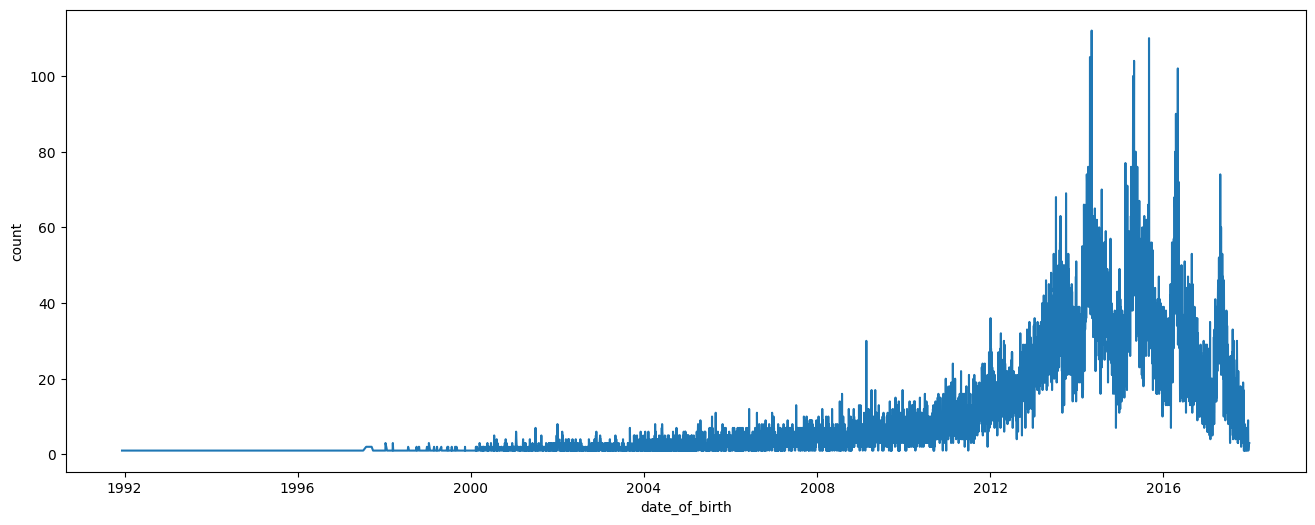

In [12]:
# Get timeseries
ts_data = shelter_outcomes['date_of_birth'].value_counts().sort_values()

# Line plot
# shelter_outcomes['date_of_birth'].value_counts().sort_values().plot.line()
plt.figure(figsize=(16, 6))
sns.lineplot(data=ts_data)
plt.show()

<Axes: xlabel='date_of_birth'>

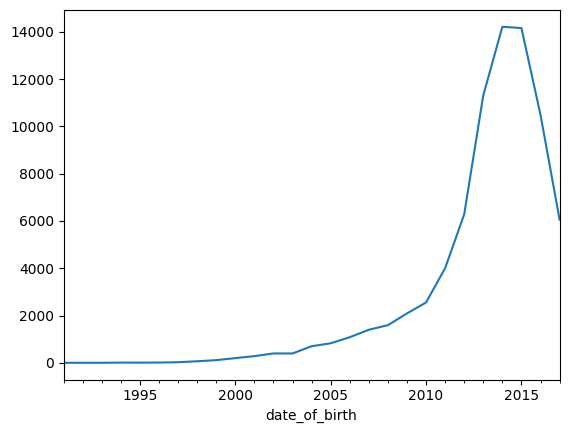

In [14]:
# shelter_outcomes['date_of_birth'].value_counts().resample('YE').sum().plot.line()
ts_data = shelter_outcomes['date_of_birth'].value_counts().resample('YE').sum()

plt.figure(figsize=(16, 6))
sns.lineplot(data=ts_data)
plt.show()

In [5]:
stocks_data = pd.read_csv("../datasets/nyse/prices.csv", parse_dates=['date'])
stocks_data['date'].str.len().value_counts()

indices = np.where(stocks_data['date'].str.len() == 19)[0]
stocks_data.loc[indices, 'date'] = stocks_data.loc[indices, 'date'].str.split().str[0]
stocks_data['date'] = pd.to_datetime(stocks_data['date'], format="%Y-%m-%d")
stocks_data = stocks_data[stocks_data['symbol'] == "GOOG"].set_index('date')
stocks_data.head()

,symbol,open,close,low,high,volume
date,,,,,,
2010-01-04,GOOG,626.951088,626.751061,624.241073,629.511067,3927000.0
2010-01-05,GOOG,627.181073,623.991055,621.541045,627.841071,6031900.0
2010-01-06,GOOG,625.861078,608.261023,606.361042,625.861078,7987100.0
2010-01-07,GOOG,609.401025,594.101005,592.651008,610.001045,12876600.0
2010-01-08,GOOG,592.000997,602.021036,589.110988,603.251034,9483900.0


<Axes: xlabel='date'>

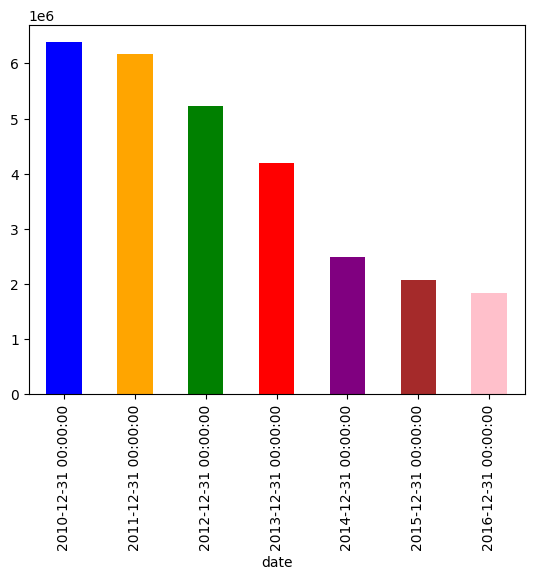

In [28]:
year_colors = ["blue", "orange", "green", "red", "purple", "brown", "pink"]
stocks_data['volume'].resample('YE').mean().plot.bar(color=year_colors)

<Axes: xlabel='y(t)', ylabel='y(t + 1)'>

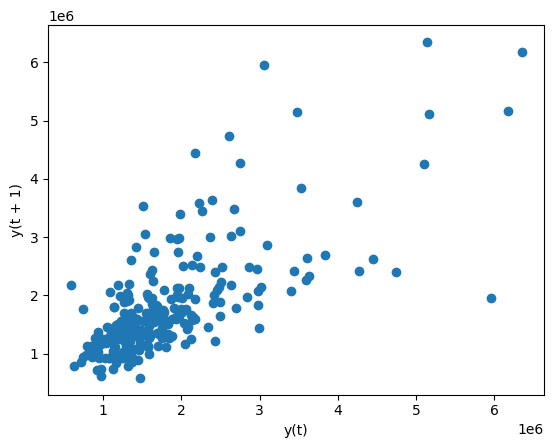

In [32]:
from pandas.plotting import lag_plot
lag_plot(stocks_data['volume'].tail(250))

<Axes: xlabel='Lag', ylabel='Autocorrelation'>

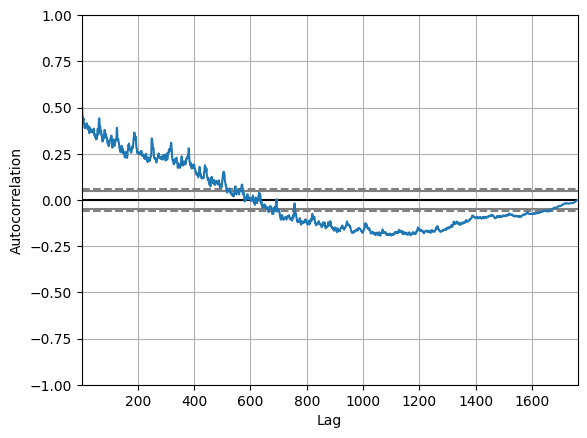

In [33]:
from pandas.plotting import autocorrelation_plot

autocorrelation_plot(stocks_data['volume'])